In [1]:
import argparse
import math
from PIL import Image, ImageDraw
import imageio.v2 as imageio  

import numpy as np
from pathlib import Path
import re


In [2]:
def make_spin_gif(input_path, output_path, n_frames, fps, bg=(255, 255, 255)):
    img = Image.open(input_path).convert("RGBA")
    w, h = img.size
 
    # Square canvas big enough that the image never gets clipped while rotating
    size = math.ceil(math.hypot(w, h))
    canvas = Image.new("RGBA", (size, size), bg + (255,))
    canvas.paste(img, ((size - w) // 2, (size - h) // 2), img)
 
    frames = []
    for i in range(n_frames):
        angle = -360 * i / n_frames  # negative = clockwise
        frame = canvas.rotate(angle, resample=Image.BICUBIC, fillcolor=bg + (255,))
        frames.append(frame.convert("RGB"))
 
    frames[0].save(
        output_path,
        save_all=True,
        append_images=frames[1:],
        duration=round(1000 / fps),  # ms per frame
        loop=0,  # loop forever
    )
    print(f"Saved {n_frames} frames at {fps} FPS -> {output_path}")
 
 

In [3]:
MM_PER_INCH = 25.4

def make_spin_frames(input_path, n_frames, bg=(255, 255, 255)):
    """Return an (n_frames, S, S, 3) uint8 array of the image doing one full clockwise revolution."""
    img = Image.open(input_path).convert("RGBA")
    w, h = img.size
 
    # Square canvas big enough that the image never gets clipped while rotating
    size = math.ceil(math.hypot(w, h))
    canvas = Image.new("RGBA", (size, size), bg + (255,))
    canvas.paste(img, ((size - w) // 2, (size - h) // 2), img)
 
    frames = []
    for i in range(n_frames):
        angle = -360 * i / n_frames  # negative = clockwise
        frame = canvas.rotate(angle, resample=Image.BICUBIC, fillcolor=bg + (255,))
        frames.append(np.array(frame.convert("RGB")))
    return np.stack(frames)
 
 
def save_gif(frames, output_path, fps):
    """Optional helper: save a frames array as a looping GIF."""
    imgs = [Image.fromarray(f) for f in frames]
    imgs[0].save(output_path, save_all=True, append_images=imgs[1:],
                 duration=round(1000 / fps), loop=0)
 
 
def make_wheel(frames, radius_mm, dpi=300, scales=1.0, frame_width_mm=None,
               radial=True, label_diameter_mm=None, hole_diameter_mm=7.24,
               bg=(0, 0, 0), output_path=None, rotate_90=False):
    """
    Arrange frames evenly around a circle to make a printable disc / vinyl label.
 
    frames             : (N, S, S, 3) array from make_spin_frames
    radius_mm          : distance from disc centre to the centre of each frame
    dpi                : print resolution; output is saved with this DPI so it prints at true size
    scales             : single float, or a list of N floats (one scale per frame)
    frame_width_mm     : physical width of a frame at scale 1.0
                         (default: 90% of the spacing between neighbouring frames)
    radial             : True = each frame's top points outward; False = all frames upright
    label_diameter_mm  : disc diameter (default: just large enough to fit all frames)
    hole_diameter_mm   : spindle hole (7.24 mm = standard record), or None for no hole
    bg                 : background colour inside the disc
    output_path        : if given, saves the image (PNG recommended)
 
    Returns an RGBA PIL image; everything outside the disc (and the hole) is transparent.
    """
    if rotate_90:
        frames = np.rot90(np.rot90(frames))

    n = len(frames)
    scales = np.broadcast_to(np.asarray(scales, dtype=float), (n,))
 
    def px(mm):
        return mm / MM_PER_INCH * dpi
 
    if frame_width_mm is None:
        frame_width_mm = 0.9 * 2 * radius_mm * math.sin(math.pi / n)
        print("Frame width: {}mm".format(frame_width_mm))
 
    if label_diameter_mm is None:
        half_extent = scales.max() * frame_width_mm * math.sqrt(2) / 2
        label_diameter_mm = 2 * (radius_mm + half_extent)
 
    D = round(px(label_diameter_mm))
    cx = cy = D / 2
    wheel = Image.new("RGBA", (D, D), bg + (255,))
 
    for i, (frame, s) in enumerate(zip(frames, scales)):
        side = max(1, round(px(frame_width_mm * s)))
        tile = Image.fromarray(frame).convert("RGBA").resize((side, side), Image.LANCZOS)
 
        theta = 2 * math.pi * i / n  # clockwise from 12 o'clock
        if radial:
            tile = tile.rotate(-math.degrees(theta), resample=Image.BICUBIC, expand=True)
 
        x = cx + px(radius_mm) * math.sin(theta)
        y = cy - px(radius_mm) * math.cos(theta)
        wheel.paste(tile, (round(x - tile.width / 2), round(y - tile.height / 2)), tile)
 
    # Clip to a circular disc and punch the spindle hole
    mask = Image.new("L", (D, D), 0)
    draw = ImageDraw.Draw(mask)
    draw.ellipse([0, 0, D - 1, D - 1], fill=255)
    if hole_diameter_mm:
        r = px(hole_diameter_mm) / 2
        draw.ellipse([cx - r, cy - r, cx + r, cy + r], fill=0)
    wheel.putalpha(mask)
 
    if output_path:
        wheel.save(output_path, dpi=(dpi, dpi))
    return wheel
 

In [5]:
%pwd

'/Users/gpir9156/Documents/Git/phd-playground/LabelArt'

In [ ]:
fname = "ms_paint.png"
out_name = "eg_png.gif"

make_spin_gif(fname, out_name, n_frames=24, fps=13+1/3)

In [ ]:
frames = make_spin_frames("ms_paint.png", n_frames=24)
make_wheel(frames, radius_mm=43, dpi=600, scales=1.0,
           label_diameter_mm=100, output_path="wheel.png")

In [4]:

def simulate_record(wheel, output_path="record.gif", dpi=None, rpm=100 / 3, fps=50,
                    revolutions=1, record_diameter_mm=300, size_px=600,
                    clockwise=True, spindle_mm=7.24, bg=(235, 235, 235)):
    """
    Put the wheel/label image on a full-size record and spin it as a looping GIF.
 
    wheel              : path to the wheel PNG, or a PIL image (then pass dpi)
    dpi                : DPI of the wheel image (read from the PNG if not given)
    rpm                : rotation speed (default 33 1/3)
    fps                : playback frame rate of the GIF (GIF timing is in 10 ms steps,
                         so 50, 25, 20, 10 fps are exact; 30 fps becomes ~33)
    revolutions        : how many turns the loop contains
    record_diameter_mm : 300 = 12" LP, 175 = 7" single
    size_px            : output image size in pixels (square)
    clockwise          : spin direction
    """
    if isinstance(wheel, str):
        wheel = Image.open(wheel)
    if dpi is None:
        dpi = wheel.info.get("dpi", (None,))[0]
        if dpi is None:
            raise ValueError("Wheel has no DPI metadata - pass dpi=...")
    wheel = wheel.convert("RGBA")
 
    # Scale label to its true size relative to the record
    px_per_mm = size_px / record_diameter_mm
    wheel_mm = wheel.width / dpi * MM_PER_INCH
    label_px = max(1, round(wheel_mm * px_per_mm))
    wheel = wheel.resize((label_px, label_px), Image.LANCZOS)
 
    # Record: black disc with faint grooves and a spindle hole
    base = Image.new("RGB", (size_px, size_px), bg)
    d = ImageDraw.Draw(base)
    c = size_px / 2
    R = size_px / 2 - 1
    d.ellipse([c - R, c - R, c + R, c + R], fill=(20, 20, 20))
    r = label_px / 2 + 3 * px_per_mm
    while r < R - 3 * px_per_mm:
        shade = int(28 + 8 * math.sin(r * 1.3))
        d.ellipse([c - r, c - r, c + r, c + r], outline=(shade,) * 3)
        r += 1.5
    h = spindle_mm * px_per_mm / 2
    d.ellipse([c - h, c - h, c + h, c + h], fill=bg)
 
    # Spin it
    n_out = round(revolutions * 60 / rpm * fps)
    step = (-1 if clockwise else 1) * 360 * revolutions / n_out
    pos = (round(c - label_px / 2), round(c - label_px / 2))
    frames = []
    for i in range(n_out):
        rot = wheel.rotate(step * i, resample=Image.BICUBIC)
        frame = base.copy()
        frame.paste(rot, pos, rot)
        frames.append(frame)
 
    frames[0].save(output_path, save_all=True, append_images=frames[1:],
                   duration=round(1000 / fps), loop=0)
    print(f"{n_out} frames @ {fps} fps, {revolutions} rev at {rpm:.2f} RPM -> {output_path}")
    return output_path

In [5]:
def simulate_record(wheel, output_path="record.mp4", dpi=None, rpm=100 / 3, fps=50,
                    revolutions=1, record_diameter_mm=300, size_px=600,
                    clockwise=True, spindle_mm=7.24, bg=(235, 235, 235)):
    """
    Put the wheel/label image on a full-size record and spin it, saved as an MP4 video.
 
    wheel              : path to the wheel PNG, or a PIL image (then pass dpi)
    dpi                : DPI of the wheel image (read from the PNG if not given)
    rpm                : rotation speed (default 33 1/3)
    output_path        : .mp4 file to write (H.264, plays in any player / browser / phone)
    fps                : video frame rate; any value works, including fractional ones like
                         strobe_fps(N). Use 60+ for smooth true-speed playback.
    revolutions        : how many turns the video contains (most players can loop it)
    n_frames           : number of frames on the wheel; if given, warns about playback aliasing
    record_diameter_mm : 300 = 12" LP, 175 = 7" single
    size_px            : output video size in pixels (square; rounded up to even for H.264)
    clockwise          : spin direction
    """
    if isinstance(wheel, str):
        wheel = Image.open(wheel)
    if dpi is None:
        dpi = wheel.info.get("dpi", (None,))[0]
        if dpi is None:
            raise ValueError("Wheel has no DPI metadata - pass dpi=...")
    wheel = wheel.convert("RGBA")
 
    size_px += size_px % 2  # H.264 (yuv420p) needs even dimensions
 
    # Scale label to its true size relative to the record
    px_per_mm = size_px / record_diameter_mm
    wheel_mm = wheel.width / dpi * MM_PER_INCH
    label_px = max(1, round(wheel_mm * px_per_mm))
    wheel = wheel.resize((label_px, label_px), Image.LANCZOS)
 
    # Record: black disc with faint grooves and a spindle hole
    base = Image.new("RGB", (size_px, size_px), bg)
    d = ImageDraw.Draw(base)
    c = size_px / 2
    R = size_px / 2 - 1
    d.ellipse([c - R, c - R, c + R, c + R], fill=(20, 20, 20))
    r = label_px / 2 + 3 * px_per_mm
    while r < R - 3 * px_per_mm:
        shade = int(28 + 8 * math.sin(r * 1.3))
        d.ellipse([c - r, c - r, c + r, c + r], outline=(shade,) * 3)
        r += 1.5
    h = spindle_mm * px_per_mm / 2
    d.ellipse([c - h, c - h, c + h, c + h], fill=bg)
 
    # Spin it
    n_out = round(revolutions * 60 / rpm * fps)
    step = (-1 if clockwise else 1) * 360 * revolutions / n_out
    pos = (round(c - label_px / 2), round(c - label_px / 2))
    with imageio.get_writer(output_path, fps=fps, codec="libx264", pixelformat="yuv420p",
                            quality=8, macro_block_size=2) as video:
        for i in range(n_out):
            rot = wheel.rotate(step * i, resample=Image.BICUBIC)
            frame = base.copy()
            frame.paste(rot, pos, rot)
            video.append_data(np.array(frame))
    print(f"{n_out} frames @ {fps:.2f} fps ({n_out / fps:.2f} s), "
          f"{revolutions} rev at {rpm:.2f} RPM -> {output_path}")
    return output_path

In [ ]:
simulate_record("wheel.png", "record.mp4", fps=60, revolutions=3)

In [6]:
def load_frames(directory, bg=(255, 255, 255), size=None):
    """
    Load every .png in a directory into an (N, S, S, 3) uint8 array for make_wheel.
 
    - Files are sorted naturally (frame2.png comes before frame10.png).
    - Transparent pixels are flattened onto `bg`.
    - Every frame is centred on a square canvas of side S (padding with `bg`), so
      non-square or mixed-size images are never stretched.
    - size: side length S in pixels. Default = the largest width/height found;
      if given, larger images are shrunk to fit and smaller ones are padded.
    """
    paths = sorted(Path(directory).glob("*.png"),
                   key=lambda p: [int(t) if t.isdigit() else t.lower()
                                  for t in re.split(r"(\d+)", p.name)])
    if not paths:
        raise FileNotFoundError(f"No .png files found in {directory}")
 
    imgs = [Image.open(p).convert("RGBA") for p in paths]
    S = size or max(max(im.size) for im in imgs)
 
    frames = []
    for im in imgs:
        im.thumbnail((S, S), Image.LANCZOS)  # only ever shrinks, keeps aspect ratio
        canvas = Image.new("RGBA", (S, S), bg + (255,))
        canvas.paste(im, ((S - im.width) // 2, (S - im.height) // 2), im)
        frames.append(np.array(canvas.convert("RGB")))
    print(f"Loaded {len(frames)} frames ({S}x{S}) from {directory}")
    return np.stack(frames)
 

Loaded 18 frames (600x600) from sequence_18_edited/
Frame width: 13.440368951420409mm


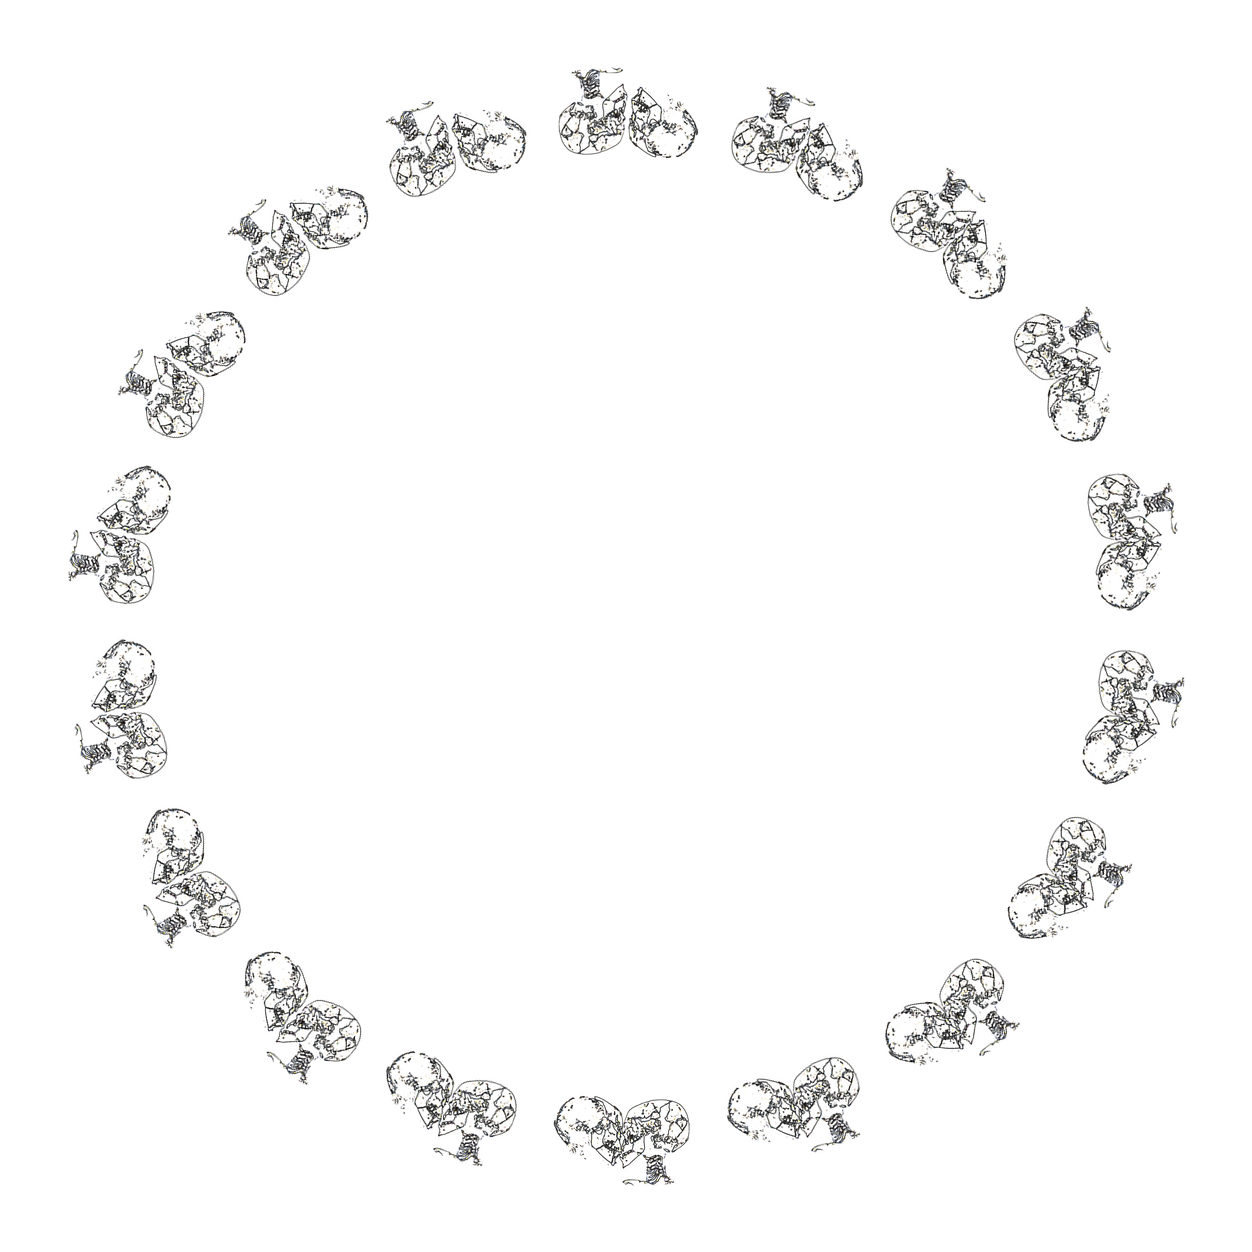

In [15]:
frame_dir = "sequence_18_edited/"
frames=load_frames(frame_dir, bg=(0, 0, 0), size=None)
make_wheel(frames, radius_mm=43, dpi=300, scales=1.0,bg=(255, 255, 255),
           label_diameter_mm=106, output_path="sequence_18_edited.pdf", rotate_90=True)


In [ ]:
0.9 * 2 * 43 * math.sin(math.pi / n)

In [ ]:
0.9 * 2 * radius_mm * math.sin(math.pi / n)

In [14]:
simulate_record("sequence_18_edited.png", "sequence_18_edited.mp4", fps=10, revolutions=5, size_px=1200, record_diameter_mm=150)

90 frames @ 10.00 fps (9.00 s), 5 rev at 33.33 RPM -> sequence_18_edited.mp4


'sequence_18_edited.mp4'